# Generative AI Project: Simple GAN for MNIST Digit Generation

**Author:** Sandip Dey  
**Model type:** Generative Adversarial Network (GAN)  
**Task:** Generate realistic handwritten digit images  
**Dataset:** MNIST (public, real handwritten digits)

This notebook implements a simple GAN, trains it, generates sample images, and evaluates output quality.


## 1. Imports and Device

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else 
                      "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")


Using device: mps


## 2. Load and Inspect MNIST

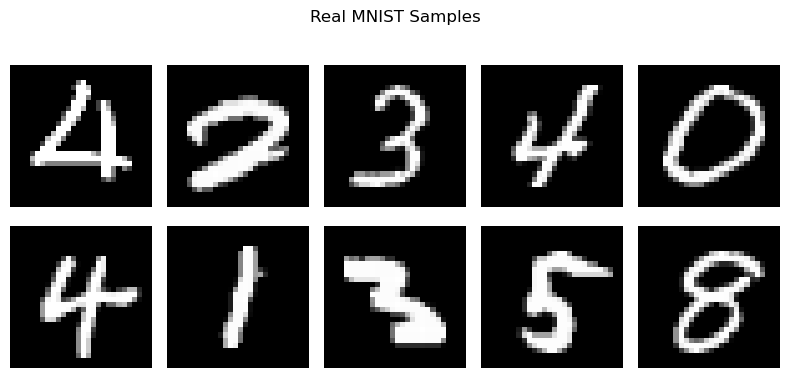

Dataset size: 60000 images
Image shape: torch.Size([128, 1, 28, 28])


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# Display real samples
real_batch = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(real_batch[0][i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Real MNIST Samples")
plt.tight_layout()
plt.show()
print(f"Dataset size: {len(train_dataset)} images")
print(f"Image shape: {real_batch[0].shape}")


## 3. GAN Architecture

**Design choices:**  
- Generator maps a 100-dimensional latent vector to a 28×28 image.  
- Discriminator classifies images as real or fake.  
- Both networks use fully connected layers with LeakyReLU.


In [3]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 28*28),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x.view(x.size(0), -1))

latent_dim = 100
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)
print(generator)
print(discriminator)


Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


## 4. Training

Epoch 1/40 | D Loss: 0.9728 | G Loss: 1.7169
Epoch 2/40 | D Loss: 1.3805 | G Loss: 1.0923
Epoch 3/40 | D Loss: 0.9868 | G Loss: 1.9019
Epoch 4/40 | D Loss: 1.3784 | G Loss: 0.7654
Epoch 5/40 | D Loss: 0.7337 | G Loss: 2.5945
Epoch 6/40 | D Loss: 0.8955 | G Loss: 2.0737
Epoch 7/40 | D Loss: 0.7872 | G Loss: 2.6110
Epoch 8/40 | D Loss: 0.9777 | G Loss: 2.8144
Epoch 9/40 | D Loss: 0.6108 | G Loss: 2.1143
Epoch 10/40 | D Loss: 0.7642 | G Loss: 1.5239
Epoch 11/40 | D Loss: 0.8235 | G Loss: 1.4579
Epoch 12/40 | D Loss: 1.2588 | G Loss: 2.4830
Epoch 13/40 | D Loss: 1.1030 | G Loss: 1.8021
Epoch 14/40 | D Loss: 1.0189 | G Loss: 0.9160
Epoch 15/40 | D Loss: 1.0395 | G Loss: 0.7615
Epoch 16/40 | D Loss: 1.4453 | G Loss: 2.0008
Epoch 17/40 | D Loss: 1.1077 | G Loss: 1.0480
Epoch 18/40 | D Loss: 1.1317 | G Loss: 1.2034
Epoch 19/40 | D Loss: 1.2048 | G Loss: 0.9348
Epoch 20/40 | D Loss: 1.2673 | G Loss: 1.6604
Epoch 21/40 | D Loss: 1.1191 | G Loss: 1.2011
Epoch 22/40 | D Loss: 1.0909 | G Loss: 1.01

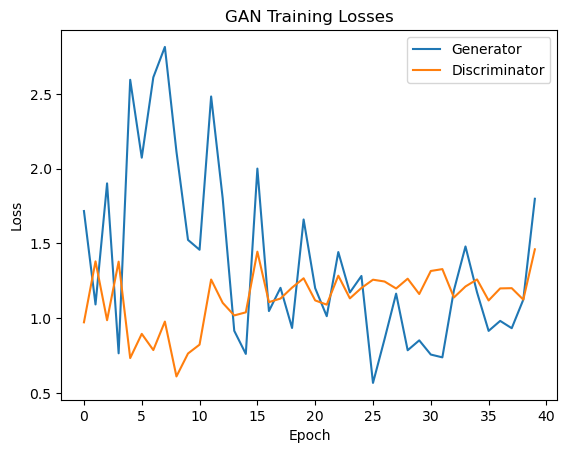

In [4]:
criterion = nn.BCELoss()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

g_losses, d_losses = [], []
epochs = 40

for epoch in range(epochs):
    for real_imgs, _ in train_loader:
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # Train Discriminator
        d_optimizer.zero_grad()
        d_real = discriminator(real_imgs)
        d_real_loss = criterion(d_real, real_labels)
        z = torch.randn(batch_size, latent_dim).to(device)
        fake_imgs = generator(z)
        d_fake = discriminator(fake_imgs.detach())
        d_fake_loss = criterion(d_fake, fake_labels)
        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        d_optimizer.step()

        # Train Generator
        g_optimizer.zero_grad()
        g_fake = discriminator(fake_imgs)
        g_loss = criterion(g_fake, real_labels)
        g_loss.backward()
        g_optimizer.step()

    g_losses.append(g_loss.item())
    d_losses.append(d_loss.item())
    print(f"Epoch {epoch+1}/{epochs} | D Loss: {d_loss.item():.4f} | G Loss: {g_loss.item():.4f}")

plt.plot(g_losses, label="Generator")
plt.plot(d_losses, label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.show()


## 5. Generate and Evaluate Outputs

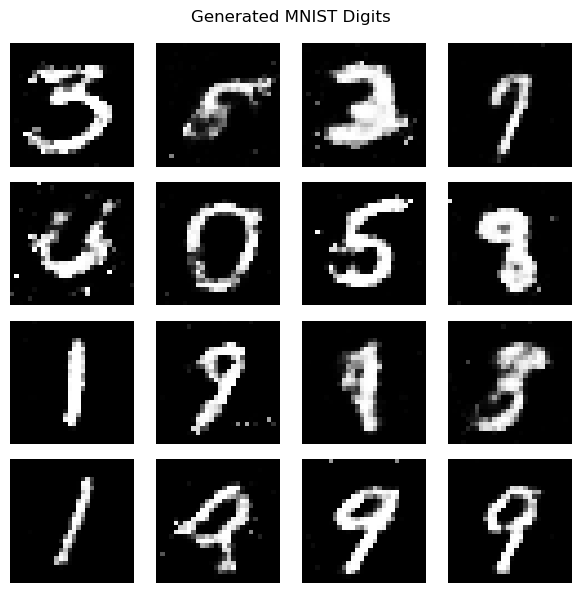

In [5]:
generator.eval()
with torch.no_grad():
    z = torch.randn(16, latent_dim).to(device)
    fake_imgs = generator(z).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(fake_imgs[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Generated MNIST Digits")
plt.tight_layout()
plt.show()


**Qualitative evaluation:**  
After 40 epochs the generator produced recognizable digit shapes, particularly for simpler digits such as 0, 1, and 7. Many samples remain blurry or contain incomplete strokes and mixed features. The final epoch losses were D Loss 1.4609 and G Loss 1.7989, indicating the adversarial balance had not fully stabilized. Strengths include learning overall digit structure; failure cases include residual mode collapse toward common digits and limited visual sharpness typical of a basic fully connected GAN.


## 6. Notebook Summary

This notebook implemented a simple Generative Adversarial Network to generate handwritten digits from the MNIST dataset (60,000 training images). The generator and discriminator were fully connected networks trained for 40 epochs with binary cross-entropy and Adam (lr=0.0002). After 40 epochs the model produced recognizable digit-like images, although many samples remained blurry or incomplete. Final epoch losses were D Loss 1.4609 and G Loss 1.7989. A practical challenge was balancing the generator and discriminator so that neither collapsed early. Observed limitations include low sharpness and occasional mode collapse, which are typical for a basic fully connected GAN even after extended training.
